# IMPORT LIBRARIES



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# Generate synthetic data for a realistic scenario

np.random.seed(42)
n_samples = 250

In [ ]:
data = {
    'Area_SqFt': np.random.randint(500,3500,size = n_samples),
    'Age_Years': np.random.randint(0,50,size= n_samples),
    'Distance_KM': np.random.randint(1,20,size = n_samples)

}

# Convert dictionary into DataFrame

In [ ]:
df = pd.DataFrame(data)
df.head(5)

,Area_SqFt,Age_Years,Distance_KM
0,1360,40,10
1,1794,32,5
2,1630,39,4
3,1595,38,2
4,2138,17,10


# 🏠 Creating the target variable

In [ ]:
df['Price_USD'] = 50000 + \
     (150 * df['Area_SqFt']) - \
     (2000 * df['Age_Years']) - \
     (5000 * df['Distance_KM']) + \
     np.random.normal(
         0,15000,
         size= n_samples
     )

# Displaying the data

In [ ]:
print("First 5 rows of the generated dataset: ")
display(df.head())

First 5 rows of the generated dataset: 


,Area_SqFt,Age_Years,Distance_KM,Price_USD
0,1360,40,10,132906.132638
1,1794,32,5,248292.226105
2,1630,39,4,199546.703219
3,1595,38,2,203993.590939
4,2138,17,10,310858.676948


In [ ]:
df.describe()

,Area_SqFt,Age_Years,Distance_KM,Price_USD
count,250.000000,250.000000,250.000000,250.000000
mean,2052.188000,26.260000,10.020000,255765.347411
std,829.127504,14.033823,5.652913,134582.651112
min,501.000000,0.000000,1.000000,-26861.035792
25%,1360.750000,16.000000,5.000000,150574.366666
50%,2028.500000,27.000000,10.000000,265863.939360
75%,2761.250000,37.750000,15.000000,358397.285007
max,3499.000000,49.000000,19.000000,558555.660026


# Visualization

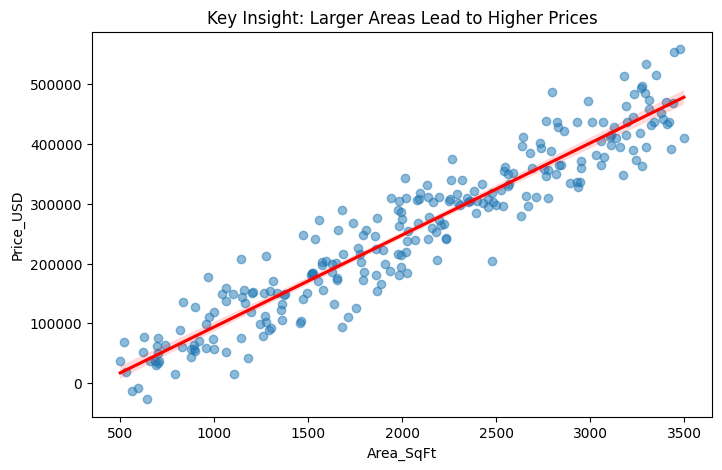

In [ ]:
import seaborn as sns

plt.figure(figsize =(8,5))

sns.regplot(
    x='Area_SqFt',
    y ='Price_USD',
    data = df,
    scatter_kws ={'alpha': 0.5},
    line_kws ={'color':'red'}
)
plt.title(
    'Key Insight: Larger Areas Lead to Higher Prices'
)
plt.show()

# **Part2: Logistic Regression**
Objective:
To implement a classification model using Python and evaluate its performance.

Concept:
Unlike Linear Regression, Logistic Regression is used for Classification. It uses the Sigmoid function to map predicted values to probabilities between 0 and 1.

Sigmoid Function:  𝜎(𝑧)=11+𝑒−𝑧
Decision Boundary: Typically, if probability > 0.5, classify as 1, else 0.
Evaluation Metric:

 Accuracy Score: The ratio of correctly predicted observations to the total observations.

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)


In [ ]:
from sklearn.datasets import load_breast_cancer

In [ ]:
data = load_breast_cancer()

In [ ]:
#data

In [ ]:
df_clf= pd.DataFrame(data.data, columns= data.feature_names)

In [ ]:
df_clf = pd.DataFrame(data.data, columns=data.feature_names)
df_clf['Target'] = data.target
df_clf.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
df_clf.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'Target'],
      dtype='object')

In [ ]:
df_clf.shape

(569, 31)

In [ ]:
# Feature Selection
selected_features =['mean radius', 'mean texture','mean area','mean concave points']

In [ ]:
# Feature Selection
# selected_features =['mean radius', 'mean texture','mean area','mean concave points']
X_clf = df_clf[selected_features].values
y_clf = df_clf['Target'].values

print(f"Selected features: {selected_features}")

Selected features: ['mean radius', 'mean texture', 'mean area', 'mean concave points']


In [ ]:
df_clf = df_clf[selected_features + ['Target']]
print(df_clf.head())

   mean radius  mean texture  mean area  mean concave points  Target
0        17.99         10.38     1001.0              0.14710       0
1        20.57         17.77     1326.0              0.07017       0
2        19.69         21.25     1203.0              0.12790       0
3        11.42         20.38      386.1              0.10520       0
4        20.29         14.34     1297.0              0.10430       0


In [ ]:
df_clf.describe()

,mean radius,mean texture,mean area,mean concave points,Target
count,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,654.889104,0.048919,0.627417
std,3.524049,4.301036,351.914129,0.038803,0.483918
min,6.981000,9.710000,143.500000,0.000000,0.000000
25%,11.700000,16.170000,420.300000,0.020310,0.000000
50%,13.370000,18.840000,551.100000,0.033500,1.000000
75%,15.780000,21.800000,782.700000,0.074000,1.000000
max,28.110000,39.280000,2501.000000,0.201200,1.000000


# 2. Split Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.33, random_state=42)

# 3. Model Training

In [ ]:
log_reg=LogisticRegression()


In [ ]:
log_reg.fit(X_train,y_train)

LogisticRegression()

# 4. Prediction

In [ ]:
y_pred = log_reg.predict(X_test)

# 5. Comprehensive Evaluation

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score


accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy Score:  {accuracy * 100:.2f}%")
print(f"Precision Score: {precision * 100:.2f}%")
print(f"Recall Score:    {recall * 100:.2f}%")
print(f"F1 Score:        {f1 * 100:.2f}%")

Accuracy Score:  90.96%
Precision Score: 91.27%
Recall Score:    95.04%
F1 Score:        93.12%


# 6. Simplified Visualization

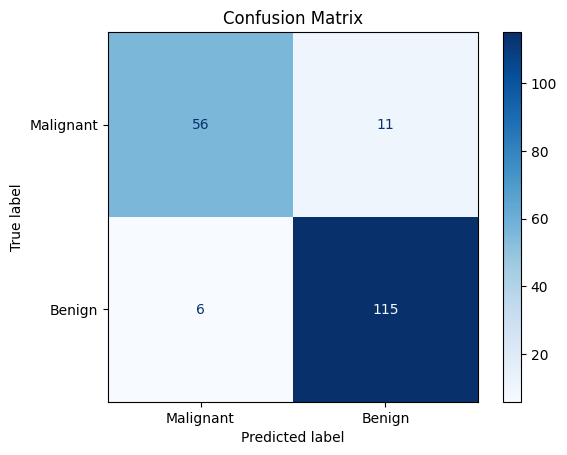

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay


ConfusionMatrixDisplay.from_estimator(log_reg, X_test, y_test,
                                      display_labels=['Malignant', 'Benign'],
                                      cmap='Blues')
plt.title('Confusion Matrix')
plt.show()